In [ ]:
# Oct 13, 2026
# Replicate performance of hmc or pymc using my infrastructure

# some references
# https://www.pymc.io/projects/examples/en/latest/ode_models/ODE_Lotka_Volterra_multiple_ways.html#inference-with-nuts

# diffrax: 
# https://colab.research.google.com/drive/1ZlK36VgWy1vBjBNXjSUg6Cb-7zeoa3jh#scrollTo=CApHqqalTKFp

# stan: 
# https://mc-stan.org/learn-stan/case-studies/lotka-volterra-predator-prey.html

In [8]:
import sys
from pathlib import Path
import time
import json

CHMC = Path.cwd().parents[1]   # AVF -> Sandbox -> CHMC
sys.path.insert(0, str(CHMC))

import equinox as eqx
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax
from jax import jit, grad
import jax.flatten_util as jfu
import jax.numpy as jnp
import jax.scipy as jsp
from jax.scipy.stats import norm
import jax.random as jr
import optax as otx
jax.config.update('jax_enable_x64', False)

from datatypes import IntegratorConfig, QP
from hamiltonian import logpdf_hamiltonian
from sampler import gen_chmc_kernel, gen_hmc_kernel


  
import pandas as pd


data = pd.read_csv("/Users/johngallagher/Documents/UCMerced/Research/GitHub/HMC-Online/hudson-bay-lynx-hare.csv", header=2)
data.columns = ['year', 'lynx', 'hare']
ts = jnp.asarray(data.year.values, dtype=float)
ts = ts-ts[0] # 0, 1, ..., 20 instead of year
# y0: prey, alpha 
# y1: preditor, beta?
#                   alpha,    β,     Ɣ,    δ,   xt0, yt0, sd
prior_μ = jnp.array([1., 0.05, 1., 0.05, jnp.log(10), jnp.log(10), -1])
prior_sd= jnp.array([0.5, 0.05, 0.5, 0.05,      1.,     1.,        1.])
#   alpha ~ N(1, 0.5)
#       β ~ N(0.05, 0.05)
#       Ɣ ~ N(1, 0.5),    
#       δ ~ N(0.05, 0.05),   
#     xt0 ~ logN(log(10), 1), 
#     yt0 ~ logN(log(10), 1), 
#      sd ~ logN(-1, 1)
def rhs(tt, YY, args):
    # unpack state and parameters
    xx, yy = YY
    alpha, β, Ɣ, δ = args
    # equations
    dx_dt = alpha * xx - β * xx * yy
    dy_dt = -Ɣ * yy + δ * xx * yy
    return dx_dt, dy_dt

def solve(θ, ts, dt=0.02):
    alpha, β, Ɣ, δ, xt0, yt0, sd = θ
    ysout = diffeqsolve(ODETerm(rhs), Tsit5(), t0=ts[0], t1=ts[-1], dt0=dt, y0=(xt0,yt0), args=(alpha, β, Ɣ, δ), saveat=SaveAt(ts=ts)).ys
    return ysout
    
def gen_log_poster(prior_mean, prior_sd, data=data, ts=ts):
    # note theta =     alpha,  β,     Ɣ,    δ,    xt0,  yt0, , sd
    #   alpha ~ N(1, 0.5)
    #       β ~ N(0.05, 0.05)
    #       Ɣ ~ N(1, 0.5),    
    #       δ ~ N(0.05, 0.05),   
    #     xt0 ~ logN(log(10), 1), 
    #     yt0 ~ logN(log(10), 1), 
    #      sd ~ logN(-1, 1)
    pred_obs, prey_obs = data.lynx.values, data.hare.values
    μ_N, sd_N = prior_mean[:4], prior_sd[:4]
    μ_LN, sd_LN = prior_mean[4:], prior_sd[4:]
    log_prey_obs, log_pred_obs = jnp.log(prey_obs), jnp.log(pred_obs)
    def log_posterior(φ):
        θ = jnp.exp(φ)
        args_N, sd = θ[:4], θ[-1]
        log_args_N = φ[:4]
        args_LN = φ[4:]
        prey_predi, pred_predi = solve(θ, ts)
        # log likelihood
        ll = (
              norm.logpdf(log_prey_obs, jnp.log(prey_predi), sd).sum()
            + norm.logpdf(log_pred_obs, jnp.log(pred_predi), sd).sum()
            )

        # Normal prior
        lp_args = (
            norm.logpdf(args_N, μ_N, sd_N).sum() 
            + log_args_N.sum()
            )
        lp_logN = norm.logpdf(args_LN, μ_LN, sd_LN).sum()
        return ll + lp_args + lp_logN
    return log_posterior
log_posterior = gen_log_poster(prior_μ, prior_sd, data, ts)
grad_log_post = jit(grad(log_posterior))

In [ ]:
HH = logpdf_hamiltonian(log_posterior, None)
gradH = grad(HH)
tau, T, tol, max_iter, mm, AA_beta = 0.01, 2., 1e-3, 10, 4, 0.95 
N = int(T/tau)
config = IntegratorConfig(τ=tau, T = T, N =N, tol=tol, max_iter=max_iter, n_pts=4, integrator='AA', AA_m=mm, AA_beta=AA_beta)

dim=7
runs, length = 4, 200

key = jr.PRNGKey(1)
key_init, key_chain = jr.split(key)

chain_keys = jr.split(key_chain,length)
chmc = jit(gen_chmc_kernel(HH, config))
hmc = jit(gen_hmc_kernel(HH,config))

φ_center = jnp.concatenate([jnp.log(prior_μ[:4]), prior_μ[4:]])
q0 = φ_center + 0.1 * jr.normal(key_init, (runs, dim))
p0 = jnp.zeros((runs,dim))

qp_init = QP(jnp.concatenate([q0[0],p0[0]])) 
init_test = [qp_init ,1,False]

scan_chmc = jax.jit(lambda init, xs: jax.lax.scan(chmc, init, xs))
lowered=scan_chmc.lower(init_test,chain_keys)
compiled = lowered.compile()
start = time.perf_counter()
_, (qps_aa, deltaHs_aa, accepted_aa) = jax.block_until_ready(compiled(init_test, chain_keys))
elapsed = time.perf_counter() - start


In [10]:
print("H finite:", jnp.isfinite(HH(qp_init)))
print("grad finite:", jax.tree.map(
    lambda x: jnp.all(jnp.isfinite(x)), gradH(qp_init)
))

H finite: True
grad finite: QP(x=Array(True, dtype=bool))


In [13]:
sum(accepted_aa)

Array(194, dtype=int32, weak_type=True)

In [11]:
deltaHs_aa

Array([-0.14447021,  0.02467346,  0.01593781,  0.00121307, -0.00180054,
        0.00411987,  0.0019989 , -0.02589417, -0.04105759, -0.03153419,
       -0.02057838, -0.02150917, -0.04938412, -0.01319218, -0.01247501,
       -0.01755905, -0.01316833, -0.05546761, -0.01983356, -0.03409767,
       -0.07141495, -0.03948498, -0.01651287, -0.01653194, -0.02265263,
       -0.02080345, -0.01399136, -0.01524544, -0.00908852, -0.01464081,
       -0.12240887, -0.01387405, -0.00988865, -0.01522255, -0.03987408,
       -0.04821491, -0.00714874, -0.01417828, -0.0209446 ,  0.01653481,
       -0.04973316, -0.01164436, -0.01850414, -0.02078724, -0.01897812,
       -0.01708603, -0.01384449, -0.00753307, -0.03101921, -0.00772095,
       -0.02618217, -0.02740669, -0.02127075, -0.0285635 , -0.01030827,
       -0.02077103, -0.01063633, -0.02269936, -0.03752327, -0.00199699,
       -0.02005672, -0.01506615, -0.01453686, -0.04109955, -0.01206303,
       -0.01396561, -0.01506138, -0.02004528, -0.01325321, -0.06

<Axes: title={'center': 'Data and Inference Model Runs \n CHMC-AA_m=4 Sampler, N_acceped = 194'}, xlabel='Year', ylabel='Pelts (Thousands)'>

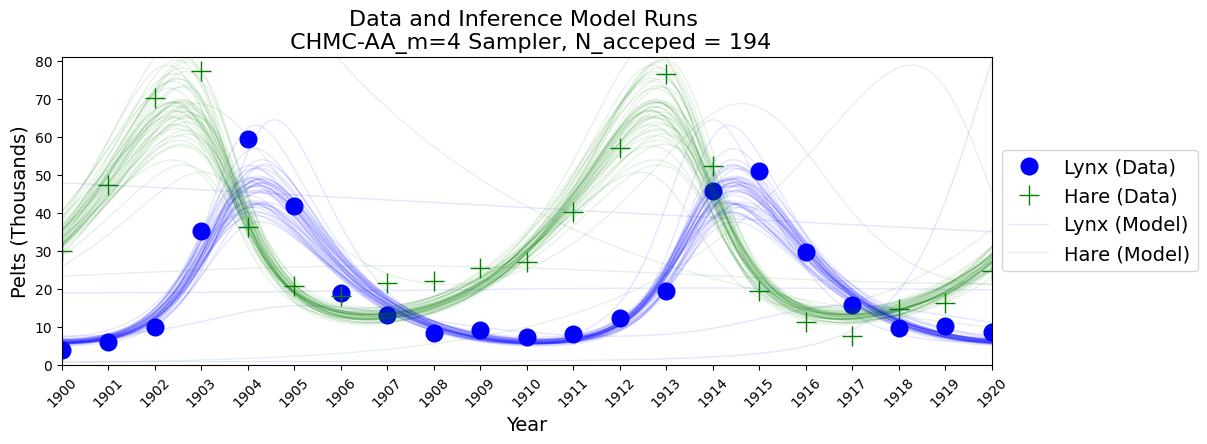

In [17]:


ts_plot = jnp.linspace(0., 20., 2001)
years_plot = jnp.asarray(ts_plot) + 1900

x_y = jax.vmap(solve, in_axes=(0,None))(jnp.exp(qps_aa.q), ts_plot)# (T, 2): [:, 0] hare, [:, 1] lynx

_, ax = plt.subplots(figsize=(12, 4))
plot_inference(ax, jnp.exp(qps_aa.q), title=f"Data and Inference Model Runs \n CHMC-AA_m=4 Sampler, N_acceped = {sum(accepted_aa)}")
# x_y = jnp.stack(x_y, axis=-1)          # (n_draws, T, 2)
# for traj in x_y:
#     plot_model(ax, traj, time=years_plot, alpha=0.1, lw=1)

In [18]:
scan_hmc = jax.jit(lambda init, xs: jax.lax.scan(hmc, init, xs))
lowered=scan_hmc.lower(init_test,chain_keys)
compiled = lowered.compile()
start = time.perf_counter()
_, (qps_hmc, deltaHs_hmc, accepted_hmc) = jax.block_until_ready(compiled(init_test, chain_keys))
elapsed = time.perf_counter() - start

ts_plot = jnp.linspace(0., 20., 2001)
years_plot = jnp.asarray(ts_plot) + 1900

x_y = jax.vmap(solve, in_axes=(0,None))(jnp.exp(qps_hmc.q), ts_plot)# (T, 2): [:, 0] hare, [:, 1] lynx

_, ax = plt.subplots(figsize=(12, 4))
plot_inference(ax, jnp.exp(qps_hmc.q), title=f"Data and Inference Model Runs \n HMC Sampler, N_acceped = {sum(accepted_hmc)}")
# x_y = jnp.stack(x_y, axis=-1)          # (n_draws, T, 2)
# for traj in x_y:
#     plot_model(ax, traj, time=years_plot, alpha=0.1, lw=1)

KeyboardInterrupt: 

<Axes: title={'center': 'Data and Inference Model Runs \n HMC Sampler, N_acceped = 191'}, xlabel='Year', ylabel='Pelts (Thousands)'>

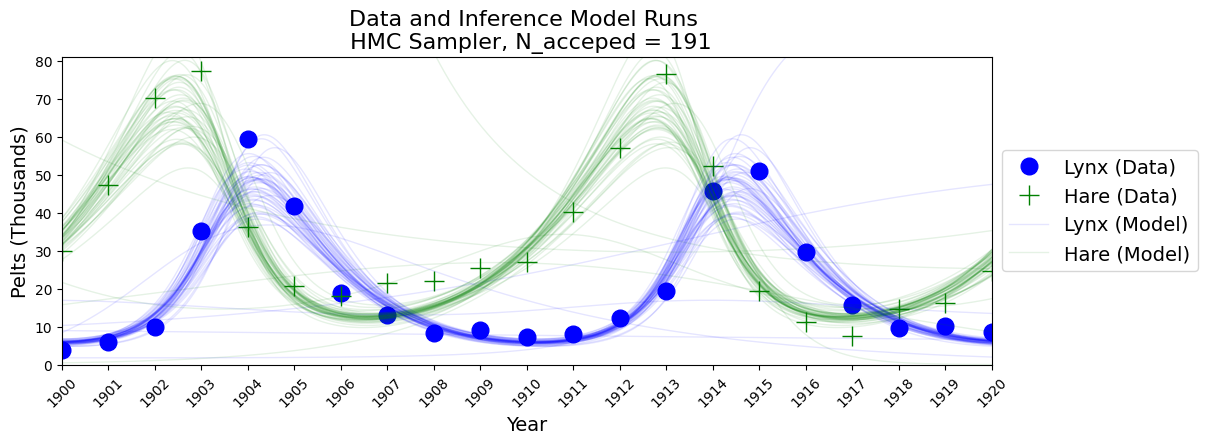

In [19]:
_, ax = plt.subplots(figsize=(12, 4))
plot_inference(ax, jnp.exp(qps_hmc.q), title=f"Data and Inference Model Runs \n HMC Sampler, N_acceped = {sum(accepted_hmc)}")
# x_y = jnp.stack(x_y, axis=-1)          # (n_draws, T, 2)
# for traj in x_y:
#     plot_model(ax, traj, time=years_plot, alpha=0.1, lw=1)

In [16]:
sum(accepted_hmc)

Array(191, dtype=int32, weak_type=True)

<Axes: title={'center': 'Data and Inference Model Runs \n HMC float 32 Sampler'}, xlabel='Year', ylabel='Pelts (Thousands)'>

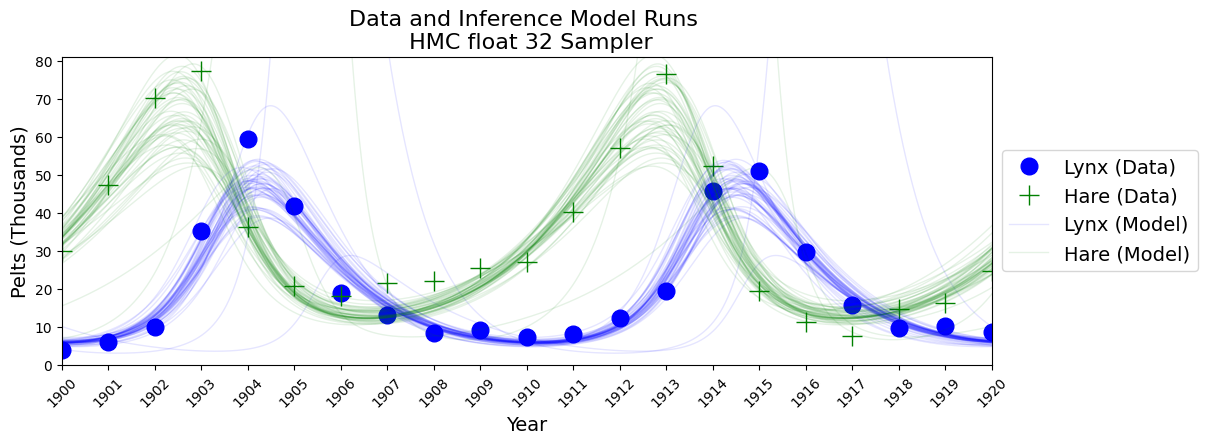

In [ ]:
# A test on float32


# scan_hmc = jax.jit(lambda init, xs: jax.lax.scan(hmc, init, xs))
# lowered=scan_hmc.lower(init_test,chain_keys)
# compiled = lowered.compile()
# start = time.perf_counter()
# _, (qps32, deltaHs32, accepted32) = jax.block_until_ready(compiled(init_test, chain_keys))
# elapsed = time.perf_counter() - start

ts_plot = jnp.linspace(0., 20., 2001)
years_plot = jnp.asarray(ts_plot) + 1900

x_y = jax.vmap(solve, in_axes=(0,None))(jnp.exp(qps32.q), ts_plot)# (T, 2): [:, 0] hare, [:, 1] lynx

_, ax = plt.subplots(figsize=(12, 4))
plot_inference(ax, jnp.exp(qps32.q), title="Data and Inference Model Runs \n HMC float 32 Sampler")
# x_y = jnp.stack(x_y, axis=-1)          # (n_draws, T, 2)
# for traj in x_y:
#     plot_model(ax, traj, time=years_plot, alpha=0.1, lw=1)

In [3]:
import numpy as np
import matplotlib.pyplot as plt



def plot_inference(ax, θ_samples, num_samples=50, key=jr.PRNGKey(0),
                   title="Hudson's Bay Company Data and\nInference Model Runs"):
    θ_flat = θ_samples.reshape(-1, θ_samples.shape[-1])          # (chains*draws, 7)
    idx = jr.choice(key, θ_flat.shape[0], (min(num_samples, θ_flat.shape[0]),), replace=False)
    sols = jax.vmap(lambda θ: jnp.stack(solve(θ, ts_plot), axis=-1))(θ_flat[idx])  # (n, T, 2)

    plot_data(ax, lw=0)
    for i, x_y in enumerate(sols):
        plot_model(ax, x_y, time=years_plot, alpha=0.1, lw=1, title=title)
        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, fontsize=14, loc="center left", bbox_to_anchor=(1, 0.5))
    return ax


# plot data function for reuse later

def plot_data(ax, lw=2, title="Hudson's Bay Company Data"):
    ax.plot(data.year, data.lynx, color="b", lw=lw, marker="o", markersize=12, label="Lynx (Data)")
    ax.plot(data.year, data.hare, color="g", lw=lw, marker="+", markersize=14, label="Hare (Data)")
    ax.legend(fontsize=14, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_xlim([1900, 1920])
    ax.set_ylim(0)
    ax.set_xlabel("Year", fontsize=14)
    ax.set_ylabel("Pelts (Thousands)", fontsize=14)
    ax.set_xticks(data.year.astype(int))
    ax.set_xticklabels(ax.get_xticks(), rotation=45)
    ax.set_title(title, fontsize=16)
    return ax
# plot model function
def plot_model(
    ax,
    x_y,
    time=np.arange(1900, 1921, 0.01),
    alpha=1,
    lw=3,
    title="Hudson's Bay Company Data and\nExample Model Run",
):
    ax.plot(time, x_y[:, 1], color="b", alpha=alpha, lw=lw, label="Lynx (Model)")
    ax.plot(time, x_y[:, 0], color="g", alpha=alpha, lw=lw, label="Hare (Model)")
    ax.legend(fontsize=14, loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_title(title, fontsize=16)
    return ax